# Fair-pay checker: is this worker paid unusually low for someone like them?

**AI for Good – Hackathon 5 "Model Showdown" · SDG 8.5 (equal pay for work of equal value) · scikit-learn**

**The problem.** In the US, women working full-time earn 83% of men's median earnings ([US Census Bureau](https://www.census.gov/newsroom/stories/equal-pay-day.html)).
Part of that gap sits *within the same job*: same work, same state, lower pay. A woman rarely knows what comparable colleagues earn, so she cannot see it.
SDG target 8.5 asks for *"equal pay for work of equal value"* for all women and men.

**The idea in plain words.** The member-advice service of a US union confederation wants to know which members may be underpaid. A simple table of median wages per job and state is not enough:
a 24-year-old nurse earning less than the median nurse in Ohio is normal, because most nurses are older and more experienced. A 50-year-old nurse with a master's degree
earning less is unusual. The model learns, from 1 million US survey answers, how likely it is that *people with this profile* (job, industry, age, education, hours)
earn above the median of their job in their state. If that is very likely, but the member earns below it, the advice service has a reason to look closer.

**Runtime:** the first run downloads 575 MB from census.gov (a few minutes). After that the notebook takes about 8 minutes on a 12-core laptop; on Colab's 2 CPUs expect roughly 20–30 minutes.

In [1]:
import time, urllib.request, zipfile
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (ConfusionMatrixDisplay, f1_score, precision_recall_curve,
                             precision_score, recall_score, roc_auc_score)
from sklearn.model_selection import GridSearchCV, GroupShuffleSplit, StratifiedGroupKFold, cross_validate
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.tree import DecisionTreeClassifier

RANDOM_STATE = 42  # one seed for every split, sample and model
print("pandas", pd.__version__, "| numpy", np.__version__, "| scikit-learn", sklearn.__version__)

pandas 2.3.3 | numpy 2.3.5 | scikit-learn 1.7.2


## 1. Frame the problem

* **Target:** `y = 1` if a worker's **hourly wage is above the median hourly wage of their occupation in their state**. Hourly, so part-time work does not count as low pay;
  per state, because pay levels differ a lot between states.
* **User and decision:** the member-advice service of a US union confederation decides whether to give a member a *"you may be underpaid"* signal and offer help with a pay negotiation.
  The signal is raised when the model says *"people like you usually earn above the median"* (a high probability) but the member earns below it.
* **Does the data match the users?** Yes: the data covers US employees in 2024, the same population as the union's members. It should not be used for workers in other countries.
* **The two mistakes:**
  * an **unjustified signal**: the low wage has a reason the data cannot see (short tenure, a small employer). The member goes into a failed negotiation and loses trust in the advice service;
  * a **missed underpaid worker**: no signal, the member stays underpaid, but can still come to the advice service on their own.

  We treat the unjustified signal as worse, so the signal uses a **strict threshold** (step 8).
* **Main metric: ROC-AUC.** The tool needs a probability that *ranks* workers well: a higher probability should really mean "more likely above the median".
  ROC-AUC measures exactly that (0.5 = coin flip, 1 = perfect). F1 does not work here: about half of all workers are above their median by definition,
  so a rule that says "above" for everyone already gets F1 = 0.66 while being useless.

## 2. Get the data and explore it

**Source:** US Census Bureau, American Community Survey (ACS) 2024 1-year Public Use Microdata Sample, person file for the whole US, plus the data dictionary. Public domain.
The file is too big for GitHub, so this cell downloads it into `data/` (only once).

In [2]:
DATA_DIR = Path("data"); DATA_DIR.mkdir(exist_ok=True)
BASE = "https://www2.census.gov/programs-surveys/acs"
FILES = {"csv_pus.zip": f"{BASE}/data/pums/2024/1-Year/csv_pus.zip",
         "PUMS_Data_Dictionary_2024.csv": f"{BASE}/tech_docs/pums/data_dict/PUMS_Data_Dictionary_2024.csv"}
for name, url in FILES.items():
    if not (DATA_DIR / name).exists():
        print("downloading", name, "...")
        urllib.request.urlretrieve(url, DATA_DIR / (name + ".part"))
        (DATA_DIR / (name + ".part")).rename(DATA_DIR / name)

COLS = ["SERIALNO", "SPORDER", "STATE", "ADJINC", "WAGP", "WKHP", "WKWN", "ESR", "COW",
        "OCCP", "INDP", "AGEP", "SCHL", "SEX", "RAC1P", "HISP", "CIT"]
with zipfile.ZipFile(DATA_DIR / "csv_pus.zip") as z:
    raw = pd.concat([pd.read_csv(z.open(n), usecols=COLS, dtype={"SERIALNO": str})
                     for n in ("psam_pusa.csv", "psam_pusb.csv")], ignore_index=True)
print(f"{len(raw):,} persons, {raw.shape[1]} columns loaded")

3,422,888 persons, 17 columns loaded


**Who is in the data.** We keep employed wage earners of working age and record what each filter drops. The hourly wage is yearly wages (in 2024 dollars, `ADJINC`)
divided by hours per week × weeks worked. Below $2 an hour is below every US minimum wage, so it is a reporting error.

In [3]:
raw["hourly"] = raw.WAGP * raw.ADJINC / 1e6 / (raw.WKHP * raw.WKWN)
FILTERS = [("age 18-64", lambda d: d.AGEP.between(18, 64)),
           ("civilian employed", lambda d: d.ESR.isin([1, 2])),
           ("employee, not self-employed", lambda d: d.COW.isin([1, 2, 3, 4, 5])),
           ("more than 4 weeks and 5 hours/week worked", lambda d: (d.WKWN > 4) & (d.WKHP > 5)),
           ("hourly wage at least $2", lambda d: d.hourly >= 2)]
workers, log = raw, []
for reason, rule in FILTERS:
    before = len(workers)
    workers = workers[rule(workers)]
    log.append((reason, before - len(workers), len(workers)))
workers = workers.copy(); del raw
pd.DataFrame(log, columns=["filter", "rows dropped", "rows left"])

,filter,rows dropped,rows left
0,age 18-64,1445925,1976963
1,civilian employed,547370,1429593
2,"employee, not self-employed",139340,1290253
3,more than 4 weeks and 5 hours/week worked,18764,1271489
4,hourly wage at least $2,3061,1268428


**Features and audit columns.** The model sees only job-related information. Sex, race/ethnicity and citizenship are **not** features: we use them only to check the model
for unequal mistakes (step 8). Occupation and industry codes get their broad group (e.g. `MED` = healthcare) from the data dictionary.

In [4]:
dd = pd.read_csv(DATA_DIR / "PUMS_Data_Dictionary_2024.csv", header=None, names=range(7), dtype=str)
def code_labels(var):
    v = dd[(dd[0] == "VAL") & (dd[1] == var) & dd[4].str.isdigit()]
    return dict(zip(v[4].astype(int), v[6]))
OCC_LABEL, IND_LABEL, STATE_LABEL = code_labels("OCCP"), code_labels("INDP"), code_labels("STATE")

workers["OCCP"] = workers.OCCP.astype(int)
workers["occ_group"] = workers.OCCP.map(OCC_LABEL).str.split("-").str[0]
workers["ind_group"] = workers.INDP.astype(int).map(IND_LABEL).str.split("-").str[0]

NUM = ["AGEP", "SCHL", "WKHP", "WKWN"]           # age, education (ordered 1-24), hours/week, weeks worked
CAT = ["OCCP", "occ_group", "ind_group", "COW"]  # occupation, occupation group, industry group, type of employer
FEATURES = NUM + CAT

# audit only, never given to the model
workers["sex"] = workers.SEX.map({1: "male", 2: "female"})
workers["race_eth"] = np.where(workers.HISP != 1, "Hispanic",
                               workers.RAC1P.map({1: "White", 2: "Black", 6: "Asian"}).fillna("Other"))
workers["citizenship"] = workers.CIT.map({1: "born citizen", 2: "born citizen", 3: "born citizen",
                                          4: "naturalised", 5: "non-citizen"})
workers["age_band"] = pd.cut(workers.AGEP, [17, 24, 34, 49, 64], labels=["18-24", "25-34", "35-49", "50-64"])
AUDIT = ["sex", "race_eth", "citizenship", "age_band"]

print(f"{len(workers):,} workers | missing values in features: {workers[FEATURES].isna().sum().sum()}"
      f" | duplicate persons: {workers.duplicated(['SERIALNO', 'SPORDER']).sum()}")
workers[NUM + ["hourly"]].describe(percentiles=[0.01, 0.5, 0.99]).round(1)

1,268,428 workers | missing values in features: 0 | duplicate persons: 0


,AGEP,SCHL,WKHP,WKWN,hourly
count,1268428.0,1268428.0,1268428.0,1268428.0,1268428.0
mean,41.2,18.9,39.5,49.5,36.7
std,13.0,3.4,10.7,8.0,44.6
min,18.0,1.0,6.0,5.0,2.0
1%,18.0,1.0,8.0,10.0,3.4
50%,41.0,20.0,40.0,52.0,26.4
99%,64.0,24.0,72.0,52.0,216.9
max,64.0,24.0,99.0,52.0,10755.3


* **No missing values** after the filters (the Census Bureau imputes missing answers), so the pipeline needs no imputer. **No person appears twice.**
* **Impossible values:** age and weeks are in range; hours and wages are top-coded by the Census Bureau, which only affects the highest earners.
* **Leakage:** wages are the outcome, so no income column is a feature. The state is not a feature either, because the target is already defined within the state.

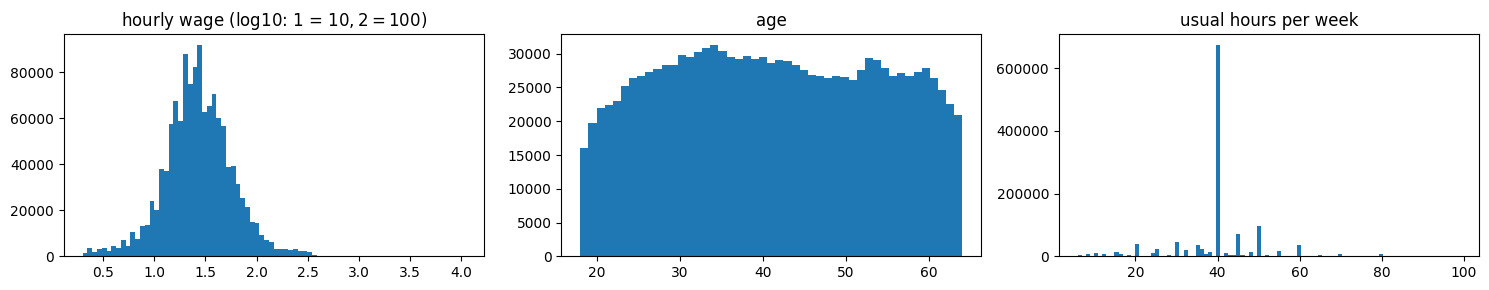

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3))
axes[0].hist(np.log10(workers.hourly), bins=80); axes[0].set(title="hourly wage (log10: 1 = $10, 2 = $100)")
axes[1].hist(workers.AGEP, bins=47); axes[1].set(title="age")
axes[2].hist(workers.WKHP, bins=94); axes[2].set(title="usual hours per week")
plt.tight_layout(); plt.show()

## 3. Split first

We set aside 20% as the test set **before** computing any median, scaling or tuning. We split **by household**: two thirds of workers live with another worker in the sample,
and housemates are similar, so nobody in the test set may have a housemate in the training set.

Then the target is built from **training data only**: the median hourly wage per state × occupation. A median of very few people is noise, so a cell needs
**at least 30 training workers**; workers in smaller cells are "not covered" and get no prediction.

In [6]:
split = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=RANDOM_STATE)
tr_idx, te_idx = next(split.split(workers, groups=workers.SERIALNO))
train_all, test_all = workers.iloc[tr_idx], workers.iloc[te_idx]
assert not set(train_all.SERIALNO) & set(test_all.SERIALNO)

MIN_CELL = 30
cells = train_all.groupby(["STATE", "OCCP"]).hourly.agg(cell_median="median", n="size").reset_index()
cells = cells[cells.n >= MIN_CELL]

def add_target(d):
    d = d.merge(cells[["STATE", "OCCP", "cell_median"]], on=["STATE", "OCCP"], how="inner")  # drops "not covered"
    return d.assign(y=(d.hourly > d.cell_median).astype(int))

train, test = add_target(train_all), add_target(test_all)
print(f"{len(cells):,} covered state x occupation cells | covered: {len(train) / len(train_all):.0%} of training workers")
print(f"share above the median: train {train.y.mean():.3f}, test {test.y.mean():.3f}")
not_covered = 1 - train.groupby("STATE").size() / train_all.groupby("STATE").size()
print("states with the most workers not covered:", not_covered.nlargest(3).rename(STATE_LABEL).round(2).to_dict())

6,415 covered state x occupation cells | covered: 86% of training workers
share above the median: train 0.491, test 0.492
states with the most workers not covered: {'Vermont/VT': 0.81, 'Alaska/AK': 0.8, 'Wyoming/WY': 0.77}


**The gender pay gap in our data.** The classes are balanced overall (by construction: half of every job earns above its median). But are women and men equally often above
the median *of their own job in their own state*? And how much do they earn compared with that median?

In [7]:
gap = train.assign(pay_vs_median=train.hourly / train.cell_median).groupby("sex").agg(
    workers=("y", "size"), share_above_median=("y", "mean"), typical_pay_vs_job_median=("pay_vs_median", "median"))
gap.round(3)

,workers,share_above_median,typical_pay_vs_job_median
sex,,,
female,436033,0.455,0.967
male,436318,0.526,1.038


Within the same job and state, **45.5% of women earn above the median, against 52.6% of men**. The typical woman earns **96.7%** of her job's median, the typical man **103.8%**: a gap of about 7 percentage points between people who do the same job in the same state.
This is the within-job gap the tool is about. It is also a warning: a model that learns "who is usually above the median" can repeat it, so step 8 checks the model's mistakes for women and men.

**Samples.** KNN compares every prediction with every training row, which is too slow on 800,000 rows. All three models are therefore tuned and compared on the **same 20,000 training workers**
and tested on **50,000 test workers**. 10% of the training households are kept apart as a **validation set** for step 6b and the signal threshold in step 8.

In [8]:
fit_idx, val_idx = next(GroupShuffleSplit(n_splits=1, test_size=0.1, random_state=RANDOM_STATE).split(train, groups=train.SERIALNO))
train_fit, val = train.iloc[fit_idx], train.iloc[val_idx]
tune = train_fit.sample(20_000, random_state=RANDOM_STATE)
test_s = test.sample(50_000, random_state=RANDOM_STATE)
X_tune, y_tune, X_test, y_test = tune[FEATURES], tune.y, test_s[FEATURES], test_s.y
print(f"tuning {len(tune):,} | validation {len(val):,} | test {len(test_s):,} workers")

tuning 20,000 | validation 87,099 | test 50,000 workers


## 4. Pre-processing inside a pipeline

One `ColumnTransformer`, fitted on training data only (inside every cross-validation fold):
* **numbers are standardised.** KNN measures distances, so without scaling "hours" (5–99) would outweigh "education" (1–24); logistic regression's penalty is only fair if all features have the same scale;
* **categories are one-hot encoded**; a category never seen in training becomes all zeros instead of an error.

In [9]:
def make_pipeline(model):
    prep = ColumnTransformer([("num", StandardScaler(), NUM),
                              ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), CAT)])
    return Pipeline([("prep", prep), ("model", model)])

## 5. Baselines

* `DummyClassifier` that always predicts the most common class ("not above"): ROC-AUC 0.5 by definition.
* The **simple alternative**: the best **single threshold on one feature** (a decision tree of depth 1, e.g. "age above 40 → above the median"). ML is only worth it if it clearly beats this.

All cross-validation uses the **same 5 folds**, stratified on the target and grouped by household.

In [10]:
folds = list(StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE).split(X_tune, y_tune, groups=tune.SERIALNO))
models, cv_result = {}, {}
for name, model in {"Baseline: most frequent class": DummyClassifier(strategy="most_frequent"),
                    "Single threshold (depth-1 tree)": DecisionTreeClassifier(max_depth=1, random_state=RANDOM_STATE)}.items():
    scores = cross_validate(make_pipeline(model), X_tune, y_tune, cv=folds, scoring="roc_auc")["test_score"]
    models[name] = make_pipeline(model).fit(X_tune, y_tune)
    cv_result[name] = ("-", f"{scores.mean():.3f} ± {scores.std():.3f}")
    print(f"{name}: CV ROC-AUC {scores.mean():.3f} ± {scores.std():.3f}")

Baseline: most frequent class: CV ROC-AUC 0.500 ± 0.000


Single threshold (depth-1 tree): CV ROC-AUC 0.583 ± 0.006


## 6. Tune with cross-validation

`GridSearchCV` on the 20,000 training workers, with the same folds and the same metric (ROC-AUC) for all three models:
* **KNN:** the number of neighbours `k`. Small k copies single neighbours (overfitting), large k averages over too many different workers (underfitting).
* **Logistic regression:** the penalty strength `C`. Small C keeps the coefficients small (simpler model), large C lets them grow.
* **HistGradientBoosting** (our own choice): a boosted tree model that is fast on large tabular data and, unlike logistic regression, can learn combinations
  such as "experience pays off more in management". We tune `max_leaf_nodes` (how complex each tree is) and `learning_rate`; early stopping picks the number of trees.

In [11]:
GRIDS = {
    "KNN": (KNeighborsClassifier(), {"model__n_neighbors": [5, 15, 51, 101, 201]}),
    "Logistic regression": (LogisticRegression(max_iter=2000), {"model__C": [0.001, 0.01, 0.1, 1, 10]}),
    "HistGradientBoosting": (HistGradientBoostingClassifier(max_iter=1000, early_stopping=True, random_state=RANDOM_STATE),
                             {"model__max_leaf_nodes": [7, 15, 31, 63], "model__learning_rate": [0.05, 0.1]}),
}
searches = {}
for name, (model, grid) in GRIDS.items():
    start = time.time()
    s = GridSearchCV(make_pipeline(model), grid, cv=folds, scoring="roc_auc", return_train_score=True, n_jobs=-1).fit(X_tune, y_tune)
    searches[name], models[name] = s, s.best_estimator_
    i = s.best_index_
    params = ", ".join(f"{k.split('__')[1]}={v}" for k, v in s.best_params_.items())
    cv_result[name] = (params, f"{s.cv_results_['mean_test_score'][i]:.3f} ± {s.cv_results_['std_test_score'][i]:.3f}")
    print(f"{name}: best {params} | CV ROC-AUC {cv_result[name][1]} | {time.time() - start:.0f} s")

KNN: best n_neighbors=101 | CV ROC-AUC 0.663 ± 0.003 | 96 s


Logistic regression: best C=0.1 | CV ROC-AUC 0.649 ± 0.006 | 9 s


HistGradientBoosting: best learning_rate=0.05, max_leaf_nodes=31 | CV ROC-AUC 0.689 ± 0.007 | 128 s


KNN | validation: {5.0: 0.616, 15.0: 0.646, 51.0: 0.66, 101.0: 0.663, 201.0: 0.662} | training: {5.0: 0.809, 15.0: 0.736, 51.0: 0.697, 101.0: 0.683, 201.0: 0.672}
Logistic regression | validation: {0.001: 0.631, 0.01: 0.643, 0.1: 0.649, 1.0: 0.646, 10.0: 0.642} | training: {0.001: 0.633, 0.01: 0.65, 0.1: 0.669, 1.0: 0.678, 10.0: 0.68}
HistGradientBoosting | validation: {7.0: 0.684, 15.0: 0.688, 31.0: 0.689, 63.0: 0.688} | training: {7.0: 0.717, 15.0: 0.741, 31.0: 0.76, 63.0: 0.786}


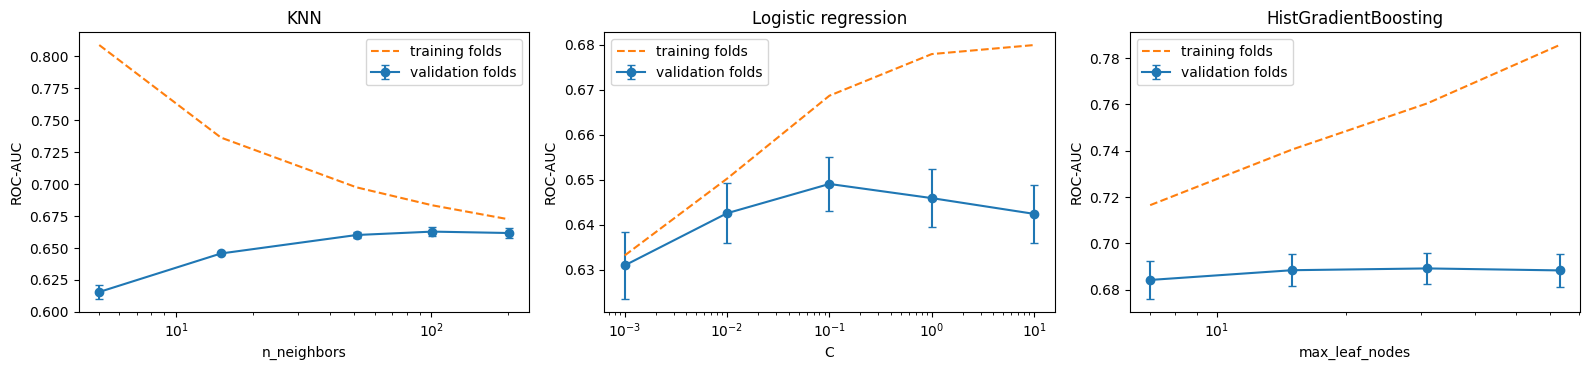

In [12]:
# score against the main hyperparameter: validation folds (mean ± sd) and training folds (dashed)
fig, axes = plt.subplots(1, 3, figsize=(16, 3.8))
for ax, (name, param) in zip(axes, [("KNN", "n_neighbors"), ("Logistic regression", "C"), ("HistGradientBoosting", "max_leaf_nodes")]):
    res = pd.DataFrame(searches[name].cv_results_)
    if name == "HistGradientBoosting":
        res = res[res.param_model__learning_rate == searches[name].best_params_["model__learning_rate"]]
    x = res[f"param_model__{param}"].astype(float)
    ax.errorbar(x, res.mean_test_score, yerr=res.std_test_score, fmt="-o", capsize=3, label="validation folds")
    ax.plot(x, res.mean_train_score, "--", label="training folds")
    ax.set(xscale="log", title=name, xlabel=param, ylabel="ROC-AUC"); ax.legend()
    print(name, "| validation:", dict(zip(x, res.mean_test_score.round(3))), "| training:", dict(zip(x, res.mean_train_score.round(3))))
plt.tight_layout(); plt.show()

**Reading the plots.** Where the training line is far above the validation line, the model memorises its training data (overfitting); where both are low and close, it is too simple (underfitting).
* **KNN** overfits at small k (k = 5: 0.81 on training, 0.62 on validation); from k = 101 on, validation stops improving while training keeps falling towards it.
* **Logistic regression** peaks at C = 0.1, and even its training score stays below 0.68: a straight-line model is too simple for this problem (underfitting).
* **HistGradientBoosting** scores highest, but the gap between training and validation grows with every extra leaf (0.76 vs 0.69 at 31 leaves): it would profit from more data.

### 6b. One extra step: give the best model more data

The comparison above is fair because every model learned from the same 20,000 rows. But we have about 800,000 training workers, and HistGradientBoosting is fast enough to use more of them
(KNN is not: it would have to search 200,000 rows for every prediction). So we refit the winner, with the same settings, on **200,000 training workers** and check on the validation households
whether that helps. This uses no test data.

In [13]:
big = train_fit.sample(200_000, random_state=RANDOM_STATE)
best_hgb = searches["HistGradientBoosting"].best_estimator_
RECOMMENDED = "HistGradientBoosting, 200k rows"
models[RECOMMENDED] = clone(best_hgb).fit(big[FEATURES], big.y)
val_s = val.sample(20_000, random_state=RANDOM_STATE)
for name in ["HistGradientBoosting", RECOMMENDED]:
    print(f"{name}: validation ROC-AUC {roc_auc_score(val_s.y, models[name].predict_proba(val_s[FEATURES])[:, 1]):.3f}")

HistGradientBoosting: validation ROC-AUC 0.697


HistGradientBoosting, 200k rows: validation ROC-AUC 0.716


## 7. Evaluate once on the test set

Every model predicts the 50,000 test workers **once**. Precision, recall and F1 are at the default threshold of 0.5.

In [14]:
rows, preds = [], {}
for name, m in models.items():
    prob = m.predict_proba(X_test)[:, 1]
    pred = (prob >= 0.5).astype(int)
    preds[name] = (pred, prob)
    if name == RECOMMENDED:
        seen = big.iloc[:20_000]  # training score on 20,000 of the rows it learned from
        train_auc = roc_auc_score(seen.y, m.predict_proba(seen[FEATURES])[:, 1])
        params, cv = cv_result["HistGradientBoosting"][0], f"{roc_auc_score(val_s.y, m.predict_proba(val_s[FEATURES])[:, 1]):.3f} (validation)"
    else:
        train_auc = roc_auc_score(y_tune, m.predict_proba(X_tune)[:, 1])
        params, cv = cv_result[name]
    rows.append({"Model": name, "Best hyperparameters": params, "Training rows": 200_000 if name == RECOMMENDED else 20_000,
                 "Train ROC-AUC": round(train_auc, 3), "CV ROC-AUC (mean ± sd)": cv, "Test ROC-AUC": round(roc_auc_score(y_test, prob), 3),
                 "Test precision": round(precision_score(y_test, pred, zero_division=0), 3),
                 "Test recall": round(recall_score(y_test, pred), 3), "Test F1": round(f1_score(y_test, pred), 3)})
comparison = pd.DataFrame(rows).set_index("Model")
comparison.to_csv("comparison_table.csv")
comparison

,Best hyperparameters,Training rows,Train ROC-AUC,CV ROC-AUC (mean ± sd),Test ROC-AUC,Test precision,Test recall,Test F1
Model,,,,,,,,
Baseline: most frequent class,-,20000,0.500,0.500 ± 0.000,0.500,0.000,0.000,0.000
Single threshold (depth-1 tree),-,20000,0.585,0.583 ± 0.006,0.589,0.554,0.834,0.666
KNN,n_neighbors=101,20000,0.685,0.663 ± 0.003,0.664,0.600,0.676,0.636
Logistic regression,C=0.1,20000,0.668,0.649 ± 0.006,0.649,0.611,0.592,0.601
HistGradientBoosting,"learning_rate=0.05, max_leaf_nodes=31",20000,0.760,0.689 ± 0.007,0.696,0.635,0.641,0.638
"HistGradientBoosting, 200k rows","learning_rate=0.05, max_leaf_nodes=31",200000,0.735,0.716 (validation),0.717,0.648,0.668,0.658


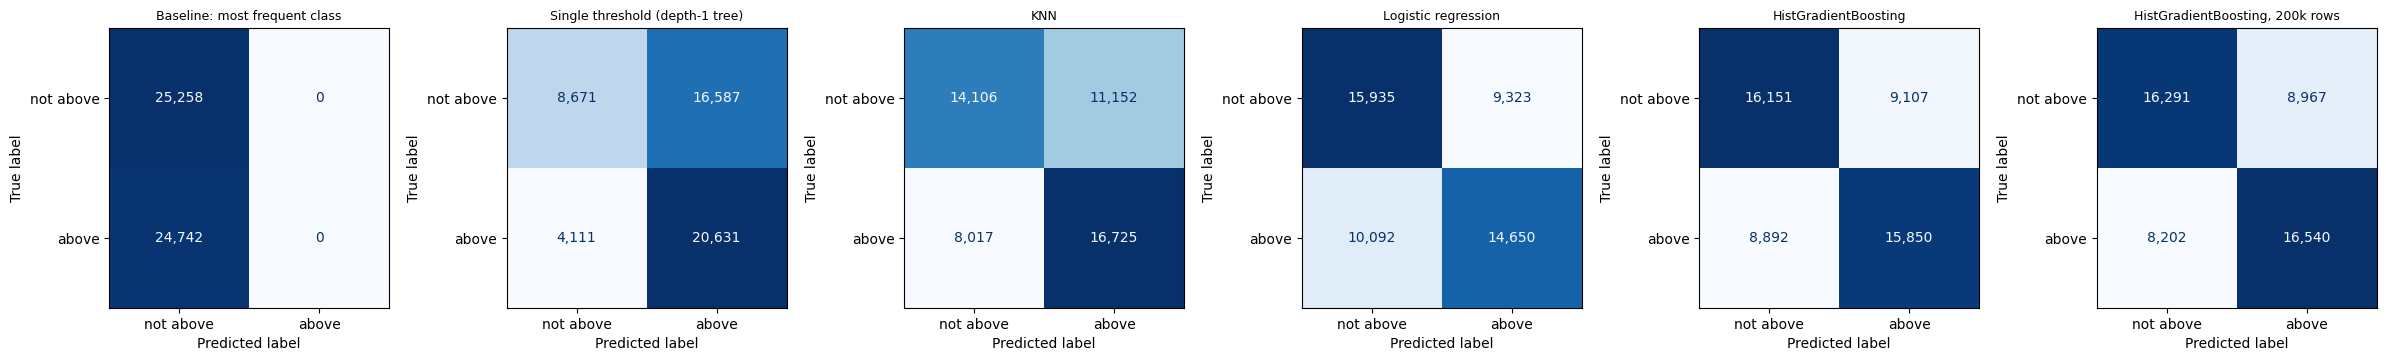

In [15]:
fig, axes = plt.subplots(1, len(preds), figsize=(4 * len(preds), 3.6))
for ax, (name, (pred, _)) in zip(axes, preds.items()):
    ConfusionMatrixDisplay.from_predictions(y_test, pred, display_labels=["not above", "above"], ax=ax,
                                            colorbar=False, values_format=",", cmap="Blues")
    ax.set_title(name, fontsize=9)
plt.tight_layout(); plt.show()

**Train vs CV vs test.** CV and test scores agree for every model, so the cross-validation estimate was honest. HistGradientBoosting on 20,000 rows has the largest gap between
training and test (overfitting); with 200,000 rows the gap shrinks and the test score rises. Logistic regression has almost no gap but a low score everywhere (underfitting).
The F1 column shows why F1 is not our metric: the single-threshold rule has a higher F1 than KNN and logistic regression, while it ranks workers far worse.

In absolute terms the best model is modest: a job profile explains part, not most, of who earns above their median. Employer, tenure, performance and discrimination are not in the data.

## 8. Look at the errors

### 8a. Women and men

The model never saw sex. Do its mistakes still differ between women and men?
*Precision* = of the workers predicted "above", how many really are; *recall* = of the workers really above, how many the model finds.

In [16]:
pred, prob = preds[RECOMMENDED]
err = test_s.assign(pred=pred, prob=prob)

def by_group(d, col, p="pred"):
    return pd.DataFrame({g: {"workers": len(s), "really above": s.y.mean(), "predicted above": s[p].mean(),
                             "precision": precision_score(s.y, s[p], zero_division=0), "recall": recall_score(s.y, s[p])}
                         for g, s in d.groupby(col, observed=True)}).T.round(3)

by_group(err, "sex")

,workers,really above,predicted above,precision,recall
female,24912.0,0.455,0.491,0.607,0.655
male,25088.0,0.535,0.530,0.686,0.680


**Proxy check.** Leaving sex out does not make the model blind to it if the other features give it away (women and men often work in different jobs and hours).
How well do the model's own features predict whether a worker is a woman? (ROC-AUC 0.5 = not at all, 1.0 = perfectly.)

In [17]:
proxy = cross_validate(make_pipeline(LogisticRegression(max_iter=2000)), X_tune, tune.sex == "female", cv=folds, scoring="roc_auc")["test_score"]
print(f"ROC-AUC when predicting 'female' from the model's features: {proxy.mean():.3f} ± {proxy.std():.3f}")

ROC-AUC when predicting 'female' from the model's features: 0.811 ± 0.008


**The signal threshold (our main mitigation).** A member gets a signal if the model's probability is at least the threshold **and** they earn below the median.
We choose the lowest threshold at which **at least 4 in 5** workers with such a profile really earn above the median, on the validation households (not the test set).
The stricter the bar, the more unusual the member's low pay is, and the less likely the signal is unjustified.

In [18]:
val_prob = models[RECOMMENDED].predict_proba(val[FEATURES])[:, 1]
prec, rec, thr = precision_recall_curve(val.y, val_prob)
THRESHOLD = float(thr[np.argmax(prec[:-1] >= 0.80)])

err["strong_profile"] = (err.prob >= THRESHOLD).astype(int)
err["signal"] = (err.strong_profile == 1) & (err.y == 0)
print(f"signal threshold {THRESHOLD:.2f}: on the test set, {precision_score(err.y, err.strong_profile):.0%} of strong profiles earn above the median;"
      f" {err.signal.mean():.1%} of all test workers get a signal")
err["above_if_strong"] = err.y.where(err.strong_profile == 1)
SIGNAL_COLS = {"strong profiles that really earn above": ("above_if_strong", "mean"), "share with a signal": ("signal", "mean")}
err.groupby("sex").agg(**SIGNAL_COLS).round(3)

signal threshold 0.73: on the test set, 80% of strong profiles earn above the median; 1.6% of all test workers get a signal


,strong profiles that really earn above,share with a signal
sex,,
female,0.759,0.019
male,0.845,0.014


### 8b. Other groups (short check)

The gender gap is our focus, but a tool for advisers should not overlook other groups. Who gets fewer signals than their pay would suggest?

In [19]:
others = pd.concat({col: err.groupby(col, observed=True).agg(really_above=("y", "mean"), **SIGNAL_COLS)
                    for col in ["race_eth", "citizenship", "age_band"]})
others.round(3)

really_above  \
race_eth    Asian                0.536   
            Black                0.469   
            Hispanic             0.434   
            Other                0.466   
            White                0.513   
citizenship born citizen         0.492   
            naturalised          0.561   
            non-citizen          0.448   
age_band    18-24                0.258   
            25-34                0.416   
            35-49                0.558   
            50-64                0.577   

                          strong profiles that really earn above  \
race_eth    Asian                                          0.802   
            Black                                          0.728   
            Hispanic                                       0.743   
            Other                                          0.762   
            White                                          0.826   
citizenship born citizen                                   0.811   
            naturalised                                    0.794   
            non-citizen                                    0.758   
age_band    18-24                                          0.500   
            25-34                                          0.839   
            35-49                                          0.810   
            50-64                                          0.798   

                          share with a signal  
race_eth    Asian                       0.028  
            Black                       0.020  
            Hispanic                    0.012  
            Other                       0.016  
            White                       0.015  
citizenship born citizen                0.014  
            naturalised                 0.030  
            non-citizen                 0.019  
age_band    18-24                       0.000  
            25-34                       0.002  
            35-49                       0.021  
            50-64                       0.027

In [20]:
# the strongest signals: who are they?
show = ["AGEP", "SCHL", "WKHP", "hourly", "cell_median", "prob"]
err[err.signal].nlargest(5, "prob").assign(occupation=lambda d: d.OCCP.map(OCC_LABEL))[["occupation"] + show].round(2)

,occupation,AGEP,SCHL,WKHP,hourly,cell_median,prob
33303,ENG-Other Engineering Technologists And Techni...,63,20.0,40.0,25.38,32.16,0.92
47748,EDU-Preschool And Kindergarten Teachers,43,22.0,8.0,7.81,15.19,0.92
19527,FIN-Tax Preparers,60,22.0,40.0,7.32,30.68,0.89
168799,MED-Clinical Laboratory Technologists And Tech...,59,24.0,50.0,22.65,24.41,0.88
54271,EDU-Preschool And Kindergarten Teachers,36,21.0,40.0,12.69,15.19,0.88


**What the errors tell us.**
* **The tool picks up the gender gap.** Among workers whose profile says "usually above the median", 76% of women really are, against 85% of men. So women with a strong profile
  are more often paid below what their profile predicts, and **women get a signal more often than men (1.9% vs 1.4%)**. That is what the tool is for.
* **But it cannot say *why*.** A signal for a woman can be the pay gap, or a reason the data does not contain (tenure, a smaller employer, wrongly reported hours).
  The model cannot tell discrimination apart from these, so a signal is a reason to talk, not proof.
* **The model can partly "see" sex** through job, industry and hours (ROC-AUC 0.81), even though sex is not an input. Its precision is lower for women than for men (0.61 vs 0.69).
* **Other groups:** Hispanic workers have the lowest share above the median of all ethnic groups, yet get the fewest signals (1.2%), because the model rarely gives them a strong profile.
  Workers under 25 almost never get one. The tool may overlook them, so advisers should reach out to these members instead of waiting for a signal.
* **The strongest signals** go to older, highly educated people in mid-paid jobs. That can be underpayment, but also a degree that is not used in this job, or a mistake in the reported wage or hours.
  An adviser has to check these first.

## 9. Recommendation

**Use HistGradientBoosting (refitted on 200,000 rows) as a triage aid for advisers, with the strict signal threshold, and never as proof.**
* It has the best CV score of the three model types, by more than the spread over the folds, and the best test ROC-AUC.
* It clearly beats the simple alternatives: the dummy (0.5) and the best single-feature rule.
* **Trade-off: explainability.** Logistic regression would be easier to explain: it gives one weight per feature (for example "older workers are more often above the median").
  HistGradientBoosting combines hundreds of small decision trees, so it cannot say *why* a member got a high probability. We accept this because the model does not make the decision:
  an adviser does, and can explain a signal with two concrete numbers (the median wage for the member's job and state, and the member's own wage).
  The extra accuracy over logistic regression (0.717 vs 0.649 on test) means fewer unjustified signals and fewer missed workers.
* **Do not use it** to tell anyone they *are* underpaid, as evidence in a negotiation, for workers outside the data (self-employed, under 18 or over 64, cells with fewer than 30 workers,
  outside the US), or by employers to set pay.

## 10. Use it: check a new (made-up) worker

Codes are in the [PUMS data dictionary](https://www2.census.gov/programs-surveys/acs/tech_docs/pums/data_dict/PUMS_Data_Dictionary_2024.csv)
(education 21 = bachelor's, 22 = master's; type of employer 1 = private company).

In [21]:
cell_median = cells.set_index(["STATE", "OCCP"]).cell_median

def check_pay(occupation, industry, state, age, education, hours_per_week, weeks_worked, employer_type, hourly_wage):
    if (state, occupation) not in cell_median.index:
        return f"Not covered: fewer than {MIN_CELL} comparable workers for occupation {occupation} in state {state}. No prediction."
    row = pd.DataFrame([{"AGEP": age, "SCHL": education, "WKHP": hours_per_week, "WKWN": weeks_worked, "OCCP": occupation,
                         "occ_group": OCC_LABEL[occupation].split("-")[0], "ind_group": IND_LABEL[industry].split("-")[0],
                         "COW": employer_type}])
    p = models[RECOMMENDED].predict_proba(row)[0, 1]
    median = cell_median[(state, occupation)]
    verdict = ("SIGNAL: paid below the median, while people like this usually earn above it. Worth a talk with an adviser."
               if hourly_wage <= median and p >= THRESHOLD else "No signal.")
    return (f"{OCC_LABEL[occupation]} in {STATE_LABEL[state]}: median ${median:.2f}/h, this worker ${hourly_wage:.2f}/h\n"
            f"Probability that people with this profile earn above the median: {p:.2f} (threshold {THRESHOLD:.2f})\n{verdict}")

# customer service representative at an insurer in Ohio, 45, master's degree, full-time, $17.50/h
print(check_pay(5240, 6991, 39, age=45, education=22, hours_per_week=40, weeks_worked=52, employer_type=1, hourly_wage=17.50), "\n")
# registered nurse in a hospital in Ohio, 41, bachelor's degree, $33/h
print(check_pay(3255, 8191, 39, age=41, education=21, hours_per_week=40, weeks_worked=52, employer_type=1, hourly_wage=33.0), "\n")
# software developer in Wyoming: too few comparable workers in the survey
print(check_pay(1021, 7380, 56, age=30, education=21, hours_per_week=40, weeks_worked=52, employer_type=1, hourly_wage=45.0))

OFF-Customer Service Representatives in Ohio/OH: median $19.52/h, this worker $17.50/h
Probability that people with this profile earn above the median: 0.88 (threshold 0.73)
SIGNAL: paid below the median, while people like this usually earn above it. Worth a talk with an adviser. 

MED-Registered Nurses in Ohio/OH: median $38.07/h, this worker $33.00/h
Probability that people with this profile earn above the median: 0.56 (threshold 0.73)
No signal. 

Not covered: fewer than 30 comparable workers for occupation 1021 in state 56. No prediction.
